# Student Performance Prediction
Predicting student final academic performance based on first period (`G1`) and second period (`G2`) grades using **Logistic Regression**.

### 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

### 2. Loading and Exploring Data

In [2]:
# Load dataset
df = pd.read_csv('StudentPerformanceDataset.csv')
df.head()

,G1,G2,G3,performance
0,5,6,6,0
1,5,5,6,0
2,7,8,10,1
3,15,14,15,1
4,6,10,10,1


In [3]:
# Dataset shape and summary
print("Dataset Shape:", df.shape)
df.info()

Dataset Shape: (395, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   G1           395 non-null    int64
 1   G2           395 non-null    int64
 2   G3           395 non-null    int64
 3   performance  395 non-null    int64
dtypes: int64(4)
memory usage: 12.5 KB


In [4]:
# Target distribution (0 = Fail/Low, 1 = Pass/Good)
print("Class Distribution:")
print(df['performance'].value_counts())

Class Distribution:
performance
1    265
0    130
Name: count, dtype: int64


### 3. Data Visualization
Scatter plot showing how G1 and G2 correlate with student passing performance.

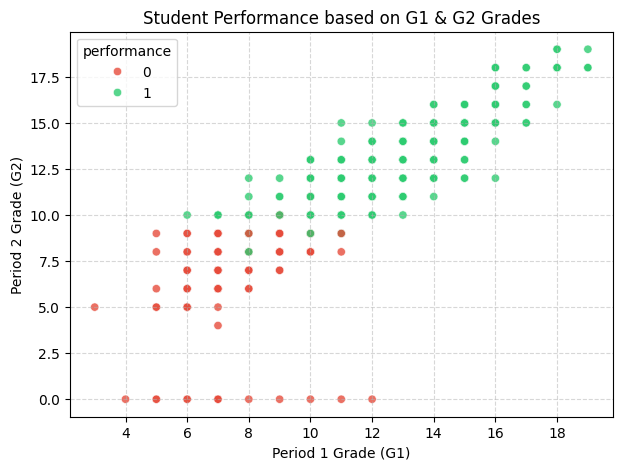

In [5]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='G1', y='G2', hue='performance', palette=['#e74c3c', '#2ecc71'], alpha=0.8)
plt.title('Student Performance based on G1 & G2 Grades')
plt.xlabel('Period 1 Grade (G1)')
plt.ylabel('Period 2 Grade (G2)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 4. Selecting Features and Target
- **Features (`X`)**: `G1`, `G2`
- **Target (`y`)**: `performance`

> *`G3` is intentionally excluded to prevent target leakage, as final performance is derived from `G3`.*

In [6]:
X = df[['G1', 'G2']]
y = df['performance']

### 5. Train-Test Split

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 316, Testing samples: 79


### 6. Training Logistic Regression Model
Fitted strictly on `X_train` and `y_train` to prevent test data leakage.

In [8]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

### 7. Model Evaluation

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.8734

Confusion Matrix:
[[24  2]
 [ 8 45]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.92      0.83        26
           1       0.96      0.85      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.89      0.86        79
weighted avg       0.89      0.87      0.88        79



### 8. Testing Custom Predictions (Without Warnings)
Passing test records inside a DataFrame so scikit-learn receives valid feature names.

In [10]:
test_cases = pd.DataFrame([
    {'G1': 12, 'G2': 13},
    {'G1': 11, 'G2': 14},
    {'G1': 18, 'G2': 17},
    {'G1': 4,  'G2': 5}
])

test_cases['Predicted_Performance'] = model.predict(test_cases)
test_cases

,G1,G2,Predicted_Performance
0,12,13,1
1,11,14,1
2,18,17,1
3,4,5,0


### 9. Saving the Model

In [11]:
model_filename = 'student_performance_model.pkl'
joblib.dump(model, model_filename)
print(f"Model successfully saved as: {model_filename}")

Model successfully saved as: student_performance_model.pkl
